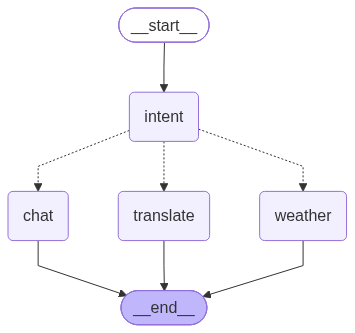

'今天北京天气如何？' -> intent=weather -> 晴 25度
'倍儿爽用英文怎么说' -> intent=translate -> "Feeling awesome!"
'你好' -> intent=chat -> 你好！很高兴见到你，有什么我可以帮忙的吗？


In [2]:
from typing import Literal

from IPython.core.display import Image
from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.constants import END, START
from langgraph.graph import MessagesState, StateGraph

# https://docs.langchain.com/oss/python/langgraph/workflows-agents

# ===============Step 1: 初始化chat模型===============
llm = init_chat_model("deepseek-v4-flash", extra_body={"thinking": {"type": "disabled"}})


# ===============Step 2: 定义State，记录用户输入、最终结果===============
class IntentState(MessagesState):
    intent: str  # 意图


# ===============Step 4: 定义Node===============
def intent_node(state: IntentState):
    intent = llm.invoke(f"""
    根据用户的请求判断用户意图，可选意图：weather、translate或chat。
    user_query: {state["messages"][-1].content}
    """)
    return {"intent": intent.content}


def weather_node(state: IntentState):
    return {"messages": [AIMessage(content="晴 25度")]}


def translate_node(state: IntentState):
    result = llm.invoke(f"""
    按照用户要求翻译，只输出翻译结果，不要任何解释。
    user_query:{state["messages"][-1].content}
    """)
    return {"messages": [result]}


def chat_node(state: IntentState):
    result = llm.invoke(state["messages"])
    return {"messages": [result]}


def intent_router(state: IntentState) -> Literal["weather", "translate", "chat"]:
    """根据意图路由到不同处理器"""
    return state["intent"]


# ===============Step 5: 创建Graph===============
builder = StateGraph(IntentState)
builder.add_node("intent", intent_node)
builder.add_node("weather", weather_node)
builder.add_node("chat", chat_node)
builder.add_node("translate", translate_node)

builder.add_edge(START, "intent")
builder.add_conditional_edges("intent", intent_router)
builder.add_edge("weather", END)
builder.add_edge("chat", END)
builder.add_edge("translate", END)

routing_graph = builder.compile()
display(Image(routing_graph.get_graph(xray=True).draw_mermaid_png()))

for q in ["今天北京天气如何？", "倍儿爽用英文怎么说", "你好"]:
    r = routing_graph.invoke({"messages": [HumanMessage(content=q)]})
    print(f"'{q}' -> intent={r['intent']} -> {r['messages'][-1].content}")